# Reading d-separation in directed acyclic graphs

A directed graph records variables and ordered relations, and it is acyclic when no directed walk returns to its starting node:

$$
G = (V,E),\qquad E\subseteq V\times V,\qquad \nexists\,(v_0,\ldots,v_k):v_0=v_k\text{ and }v_{i-1}\to v_i\ \forall i.
$$

Here, $G$ is the graph, $V$ is its node set, $E$ is its directed-edge set, $v_i$ is the node visited at step $i$, $k$ is the number of steps in a proposed cycle, and $\nexists$ states that no directed cycle exists.

,Motif,Pattern,Middle node,Path state without conditioning
0,Chain,X to M to Y,M,Active
1,Common cause,X from C to Y,C,Active
2,Collider,X to K from Y,K,Blocked


,Motif,Nodes,Directed edges,Acyclic,Roots,Sinks
0,Chain,3,2,True,1,1
1,Common cause,3,2,True,1,2
2,Collider,3,2,True,2,1


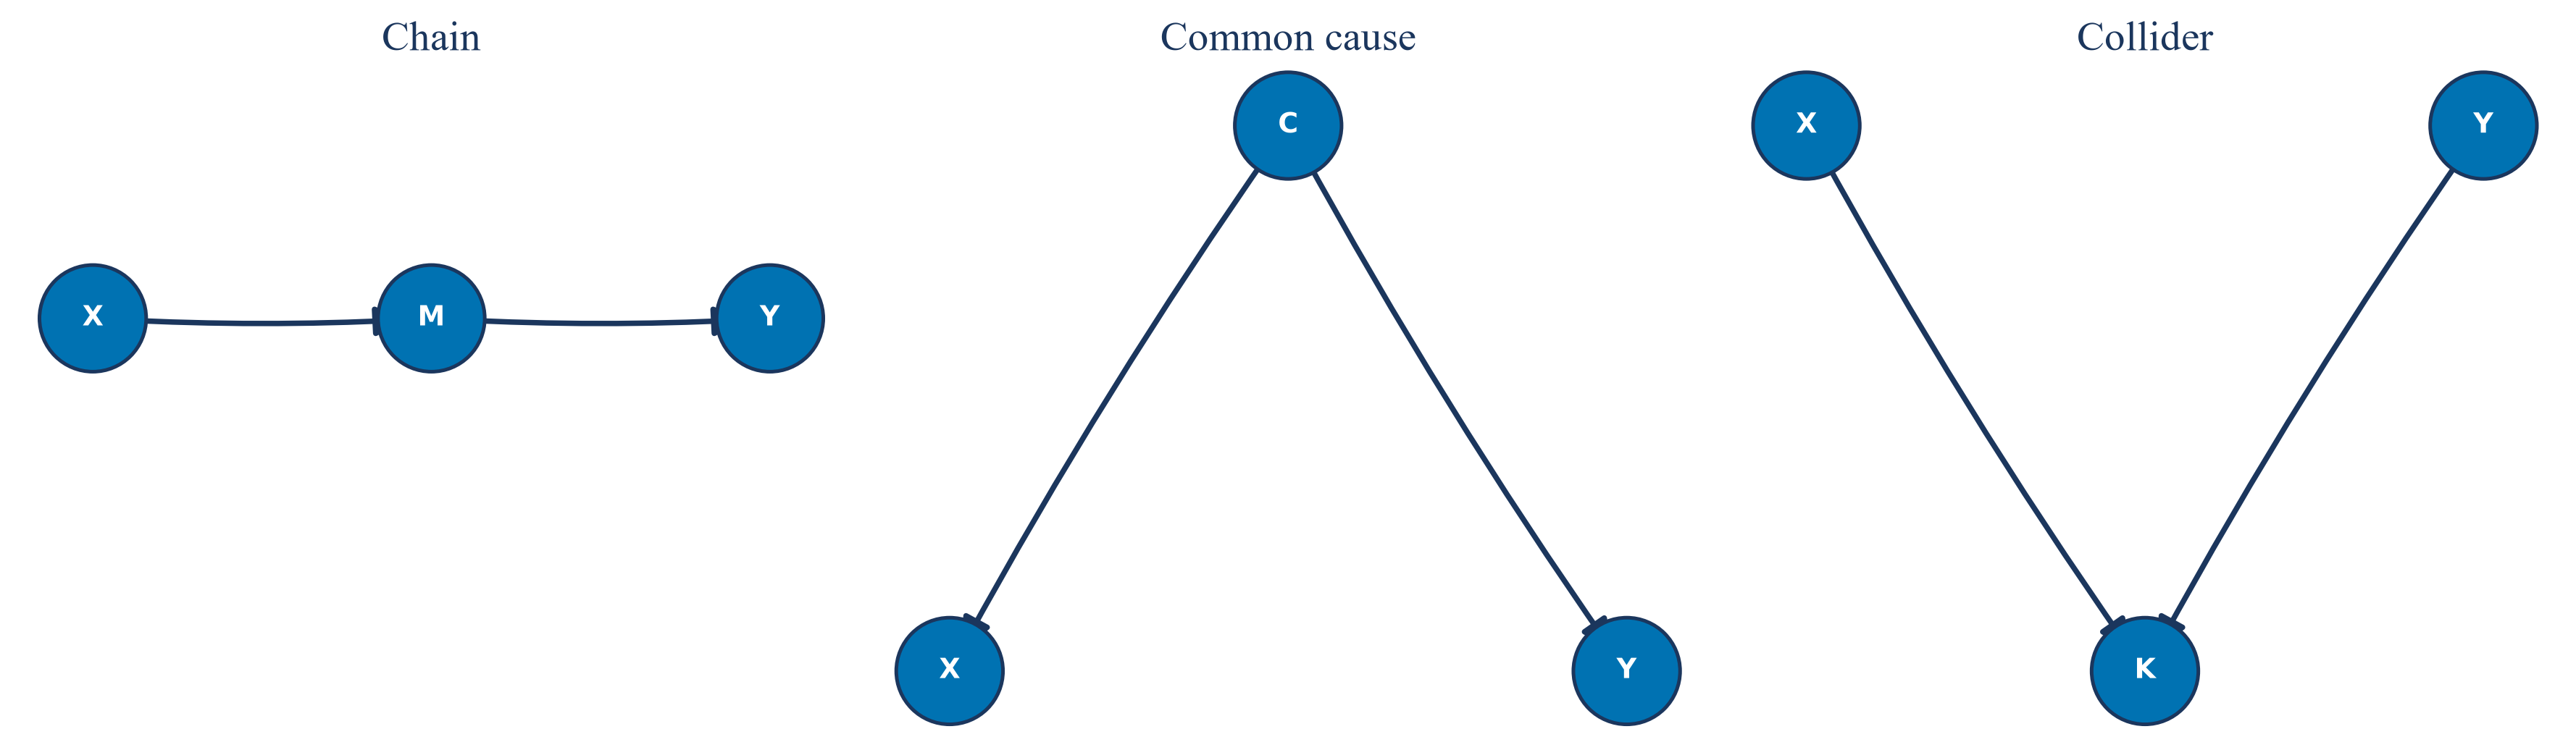

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import re
import sys
import warnings
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Image

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]

FIGURES = ROOT / "outputs" / "figures" / "01_causal_roles"
TABLES = ROOT / "outputs" / "tables" / "01_causal_roles"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5", "muted": "#5C6670"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def display_float(value):
    if not np.isfinite(value):
        return str(value)
    nearest_integer = round(float(value))
    if np.isclose(value, nearest_integer, atol=1e-12):
        return str(int(nearest_integer))
    if abs(value) < 5e-13:
        return "0"
    return f"{value:.6f}".rstrip("0").rstrip(".")

pd.set_option("display.float_format", display_float)

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True, position="tbp"):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position=position))
    if fit:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{adjustbox}{max width=\textwidth}" + "\n" + r"\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}" + "\n" + r"\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = re.sub(r"(?<![A-Za-z])(?:nan|NaN)(?![A-Za-z])", "Not available", latex)
    latex = re.sub(r"(?<![A-Za-z])inf(?![A-Za-z])", "No finite value", latex)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_figure(figure, stem):
    figure.savefig(FIGURES / f"{stem}.png", bbox_inches="tight", dpi=300)
    figure.savefig(FIGURES / f"{stem}.pdf", bbox_inches="tight")
    display(Image(filename=str(FIGURES / f"{stem}.png")))
    plt.close(figure)

def draw_directed_graph(axis, graph, positions, title, colors=None, labels=None, edge_styles=None, node_size=1250, font_size=9):
    node_colors = [palette["cyan"] if colors is None else colors.get(node, palette["cyan"]) for node in graph.nodes]
    nx.draw_networkx_nodes(graph, positions, ax=axis, node_color=node_colors, node_size=node_size, edgecolors=palette["text"], linewidths=1.2)
    nx.draw_networkx_labels(graph, positions, ax=axis, labels=labels, font_color=palette["background"], font_weight="bold", font_size=font_size)
    if edge_styles is None:
        nx.draw_networkx_edges(graph, positions, ax=axis, edge_color=palette["text"], width=1.8, arrows=True, arrowsize=20, connectionstyle="arc3,rad=0.03")
    else:
        for edge in graph.edges:
            style = edge_styles.get(edge, "solid")
            nx.draw_networkx_edges(graph, positions, ax=axis, edgelist=[edge], edge_color=palette["text"], width=1.8, style=style, arrows=True, arrowsize=20, connectionstyle="arc3,rad=0.03")
    axis.set_title(title)
    axis.set_axis_off()

def partial_correlation(x, y, controls=None):
    x_values = np.asarray(x, dtype=float).reshape(-1)
    y_values = np.asarray(y, dtype=float).reshape(-1)
    if controls is None or np.asarray(controls).size == 0:
        return float(np.corrcoef(x_values, y_values)[0, 1])
    control_values = np.asarray(controls, dtype=float)
    if control_values.ndim == 1:
        control_values = control_values.reshape(-1, 1)
    design = np.column_stack([np.ones(len(control_values)), control_values])
    x_residual = x_values - design @ np.linalg.lstsq(design, x_values, rcond=None)[0]
    y_residual = y_values - design @ np.linalg.lstsq(design, y_values, rcond=None)[0]
    return float(np.corrcoef(x_residual, y_residual)[0, 1])

def regression_summary(frame, outcome, treatment, controls):
    columns = [treatment] + list(controls)
    design = np.column_stack([np.ones(len(frame)), frame[columns].to_numpy(dtype=float)])
    response = frame[outcome].to_numpy(dtype=float)
    coefficients = np.linalg.lstsq(design, response, rcond=None)[0]
    fitted = design @ coefficients
    residual = response - fitted
    total = response - response.mean()
    r_squared = 1.0 - float(residual @ residual) / float(total @ total)
    return float(coefficients[1]), r_squared

def path_is_active(graph, path, conditioned):
    conditioned_set = set(conditioned)
    collider_openers = set(conditioned_set)
    for node in conditioned_set:
        collider_openers.update(nx.ancestors(graph, node))
    for index in range(1, len(path) - 1):
        previous_node = path[index - 1]
        middle_node = path[index]
        next_node = path[index + 1]
        collider = graph.has_edge(previous_node, middle_node) and graph.has_edge(next_node, middle_node)
        if collider and middle_node not in collider_openers:
            return False
        if not collider and middle_node in conditioned_set:
            return False
    return True

def path_records(graph, source, target, conditioned):
    records = []
    paths = list(nx.all_simple_paths(graph.to_undirected(), source=source, target=target))
    for path in paths:
        colliders = []
        for index in range(1, len(path) - 1):
            previous_node = path[index - 1]
            middle_node = path[index]
            next_node = path[index + 1]
            if graph.has_edge(previous_node, middle_node) and graph.has_edge(next_node, middle_node):
                colliders.append(middle_node)
        records.append({"Path": " - ".join(path), "Conditioning set": ", ".join(sorted(conditioned)) if conditioned else "None", "Collider nodes": ", ".join(colliders) if colliders else "None", "Active": path_is_active(graph, path, conditioned)})
    return records

def fit_sem_covariance(covariance, graph, nodes):
    covariance_values = np.asarray(covariance, dtype=float)
    node_index = {node: index for index, node in enumerate(nodes)}
    coefficients = np.zeros_like(covariance_values)
    residual_variances = np.zeros(len(nodes), dtype=float)
    for node in nodes:
        row = node_index[node]
        parents = list(graph.predecessors(node))
        if parents:
            parent_indices = [node_index[parent] for parent in parents]
            beta = covariance_values[row, parent_indices] @ np.linalg.inv(covariance_values[np.ix_(parent_indices, parent_indices)])
            coefficients[row, parent_indices] = beta
            residual_variances[row] = covariance_values[row, row] - beta @ covariance_values[parent_indices, row]
        else:
            residual_variances[row] = covariance_values[row, row]
    transform = np.linalg.inv(np.eye(len(nodes)) - coefficients)
    implied = transform @ np.diag(residual_variances) @ transform.T
    return coefficients, residual_variances, implied

def role_color(role):
    mapping = {"confounder": palette["amber"], "mediator": palette["green"], "collider": palette["rose"], "instrument": palette["violet"], "ancestor_of_outcome": palette["cyan"], "descendant_of_outcome": palette["muted"], "descendant_of_treatment": palette["muted"], "independent": palette["grid"]}
    return mapping.get(role, palette["cyan"])

motifs = {
    "Chain": nx.DiGraph([("X", "M"), ("M", "Y")]),
    "Common cause": nx.DiGraph([("C", "X"), ("C", "Y")]),
    "Collider": nx.DiGraph([("X", "K"), ("Y", "K")]),
}
motif_definitions = pd.DataFrame([
    {"Motif": "Chain", "Pattern": "X to M to Y", "Middle node": "M", "Path state without conditioning": "Active"},
    {"Motif": "Common cause", "Pattern": "X from C to Y", "Middle node": "C", "Path state without conditioning": "Active"},
    {"Motif": "Collider", "Pattern": "X to K from Y", "Middle node": "K", "Path state without conditioning": "Blocked"},
])
motif_edges = pd.DataFrame([{"Motif": name, "From": source, "To": target} for name, graph in motifs.items() for source, target in graph.edges])
structure_rows = []
for name, graph in motifs.items():
    structure_rows.append({"Motif": name, "Nodes": graph.number_of_nodes(), "Directed edges": graph.number_of_edges(), "Acyclic": nx.is_directed_acyclic_graph(graph), "Roots": sum(graph.in_degree(node) == 0 for node in graph.nodes), "Sinks": sum(graph.out_degree(node) == 0 for node in graph.nodes)})
graph_structure_summary = pd.DataFrame(structure_rows)
save_table(motif_definitions, "motif_definitions", "Three elementary path motifs.", "tab:chapter23-motif-definitions")
save_table(motif_edges, "motif_edges", "Directed edges in the three elementary motifs.", "tab:chapter23-motif-edges")
save_table(graph_structure_summary, "graph_structure_summary", "Structural checks for the elementary motifs.", "tab:chapter23-graph-structure")
display(motif_definitions)
display(graph_structure_summary)

figure, axes = plt.subplots(1, 3, figsize=(12, 3.6))
positions = {"X": (0, 0), "M": (1, 0), "Y": (2, 0), "C": (1, 1), "K": (1, -1)}
for axis, (name, graph) in zip(axes, motifs.items()):
    draw_directed_graph(axis, graph, {node: positions[node] for node in graph.nodes}, name)
figure.tight_layout()
save_figure(figure, "elementary_causal_motifs")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Determining whether a graph path is blocked

A path is active given a conditioning set when every noncollider on the path is outside that set and every collider has itself or a descendant in the set:

$$
A(\pi\mid S)=\prod_{m\in N(\pi)}\mathbf 1\{m\notin S\}\prod_{c\in C(\pi)}\mathbf 1\{c\in\operatorname{An}(S)\},
$$

Here, $\pi$ is a path, $S$ is the conditioning set, $N(\pi)$ is the set of internal noncolliders, $C(\pi)$ is the set of internal colliders, $\operatorname{An}(S)$ contains the nodes in $S$ and their ancestors, $\mathbf 1\{\cdot\}$ is an indicator, and $A(\pi\mid S)$ equals one exactly when the path is active.

,Motif,Path,Conditioning set,Collider nodes,Path state
0,Chain,X - M - Y,None,None,Active
1,Chain,X - M - Y,M,None,Blocked
2,Common cause,X - C - Y,None,None,Active
3,Common cause,X - C - Y,C,None,Blocked
4,Collider,X - K - Y,None,K,Blocked
5,Collider,X - K - Y,K,K,Active


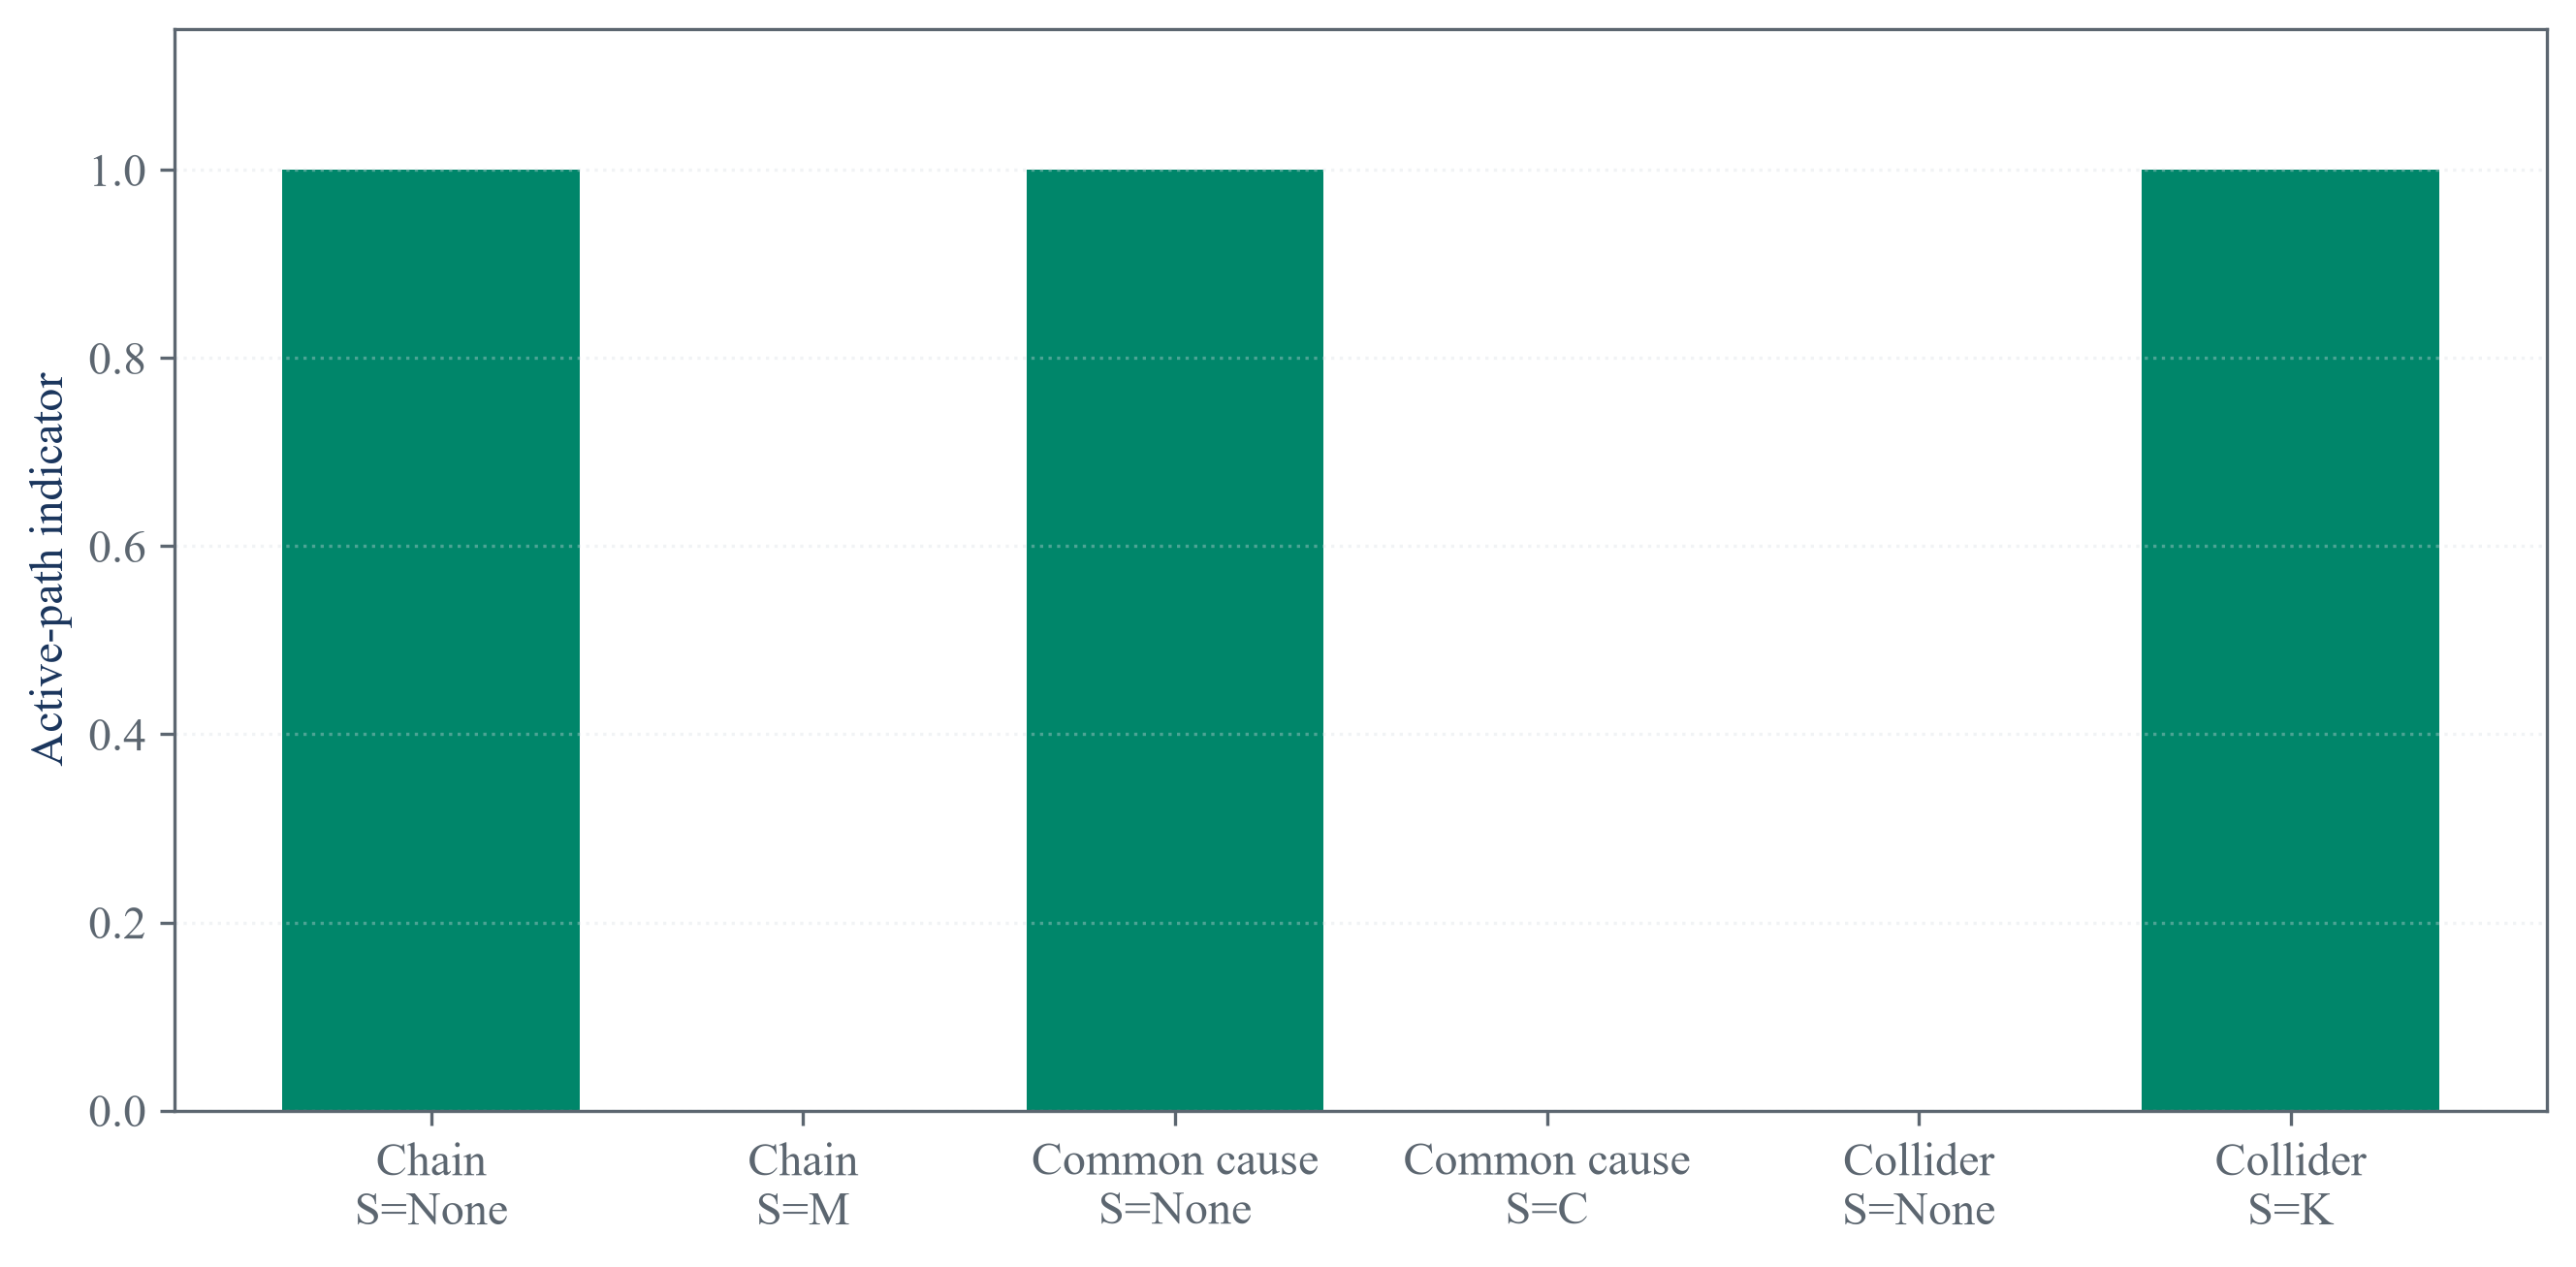

In [2]:
conditioning_cases = {
    "Chain": [set(), {"M"}],
    "Common cause": [set(), {"C"}],
    "Collider": [set(), {"K"}],
}
path_rows = []
for name, graph in motifs.items():
    for conditioned in conditioning_cases[name]:
        path_rows.extend(path_records(graph, "X", "Y", conditioned))
        path_rows[-1]["Motif"] = name
motif_path_status = pd.DataFrame(path_rows)[["Motif", "Path", "Conditioning set", "Collider nodes", "Active"]]
motif_path_status["Path state"] = motif_path_status["Active"].map({True: "Active", False: "Blocked"})
save_table(motif_path_status.drop(columns="Active"), "motif_path_status", "Path states before and after conditioning on the middle node.", "tab:chapter23-motif-path-status")
display(motif_path_status.drop(columns="Active"))

active_counts = motif_path_status.assign(Value=motif_path_status["Active"].astype(int))
figure, axis = plt.subplots(figsize=(9, 4.5))
labels = [f"{row['Motif']}\nS={row['Conditioning set']}" for _, row in active_counts.iterrows()]
colors = [palette["green"] if value else palette["rose"] for value in active_counts["Value"]]
axis.bar(labels, active_counts["Value"], color=colors)
axis.set_ylabel("Active-path indicator")
axis.set_ylim(0, 1.15)
axis.grid(axis="y", alpha=0.35)
figure.tight_layout()
save_figure(figure, "motif_path_states")

## Graph Factorization

A probability distribution compatible with a directed acyclic graph factors into one conditional term for each node given its parents:

$$
p(x_1,\ldots,x_p)=\prod_{j=1}^{p}p\!\left(x_j\mid x_{\operatorname{pa}(j)}\right).
$$

Here, $p$ is the number of variables, $x_j$ is the realized value of node $j$, $\operatorname{pa}(j)$ is the parent set of node $j$, $x_{\operatorname{pa}(j)}$ contains the realized parent values, and $p(\cdot)$ denotes a joint or conditional density.

In [3]:
motif_factorizations = pd.DataFrame([
    {"Motif": "Chain", "Factorization": "p(X) p(M | X) p(Y | M)", "Implied separation": "X independent of Y given M"},
    {"Motif": "Common cause", "Factorization": "p(C) p(X | C) p(Y | C)", "Implied separation": "X independent of Y given C"},
    {"Motif": "Collider", "Factorization": "p(X) p(Y) p(K | X,Y)", "Implied separation": "X independent of Y before conditioning"},
])
save_table(motif_factorizations, "motif_factorizations", "Factorizations and elementary graph separations.", "tab:chapter23-motif-factorizations")
display(motif_factorizations)

,Motif,Factorization,Implied separation
0,Chain,p(X) p(M | X) p(Y | M),X independent of Y given M
1,Common cause,p(C) p(X | C) p(Y | C),X independent of Y given C
2,Collider,"p(X) p(Y) p(K | X,Y)",X independent of Y before conditioning


## Comparing marginal association with conditional association

With one conditioning variable, partial correlation removes the two linear associations that pass through that variable:

$$
\rho_{XY\cdot Z}=\frac{\rho_{XY}-\rho_{XZ}\rho_{YZ}}{\sqrt{(1-\rho_{XZ}^{2})(1-\rho_{YZ}^{2})}}.
$$

Here, $X$ and $Y$ are the variables being compared, $Z$ is the conditioning variable, $\rho_{XY}$ is their marginal correlation, $\rho_{XZ}$ and $\rho_{YZ}$ are their correlations with $Z$, and $\rho_{XY\cdot Z}$ is their partial correlation after linear adjustment for $Z$.

,Motif,Observations,Marginal correlation,Correlation after conditioning,Absolute change
0,Chain,20000,0.522134,0.011725,0.51041
1,Common cause,20000,0.442947,0.005221,0.437726
2,Collider,20000,0.010745,-0.434367,0.445111


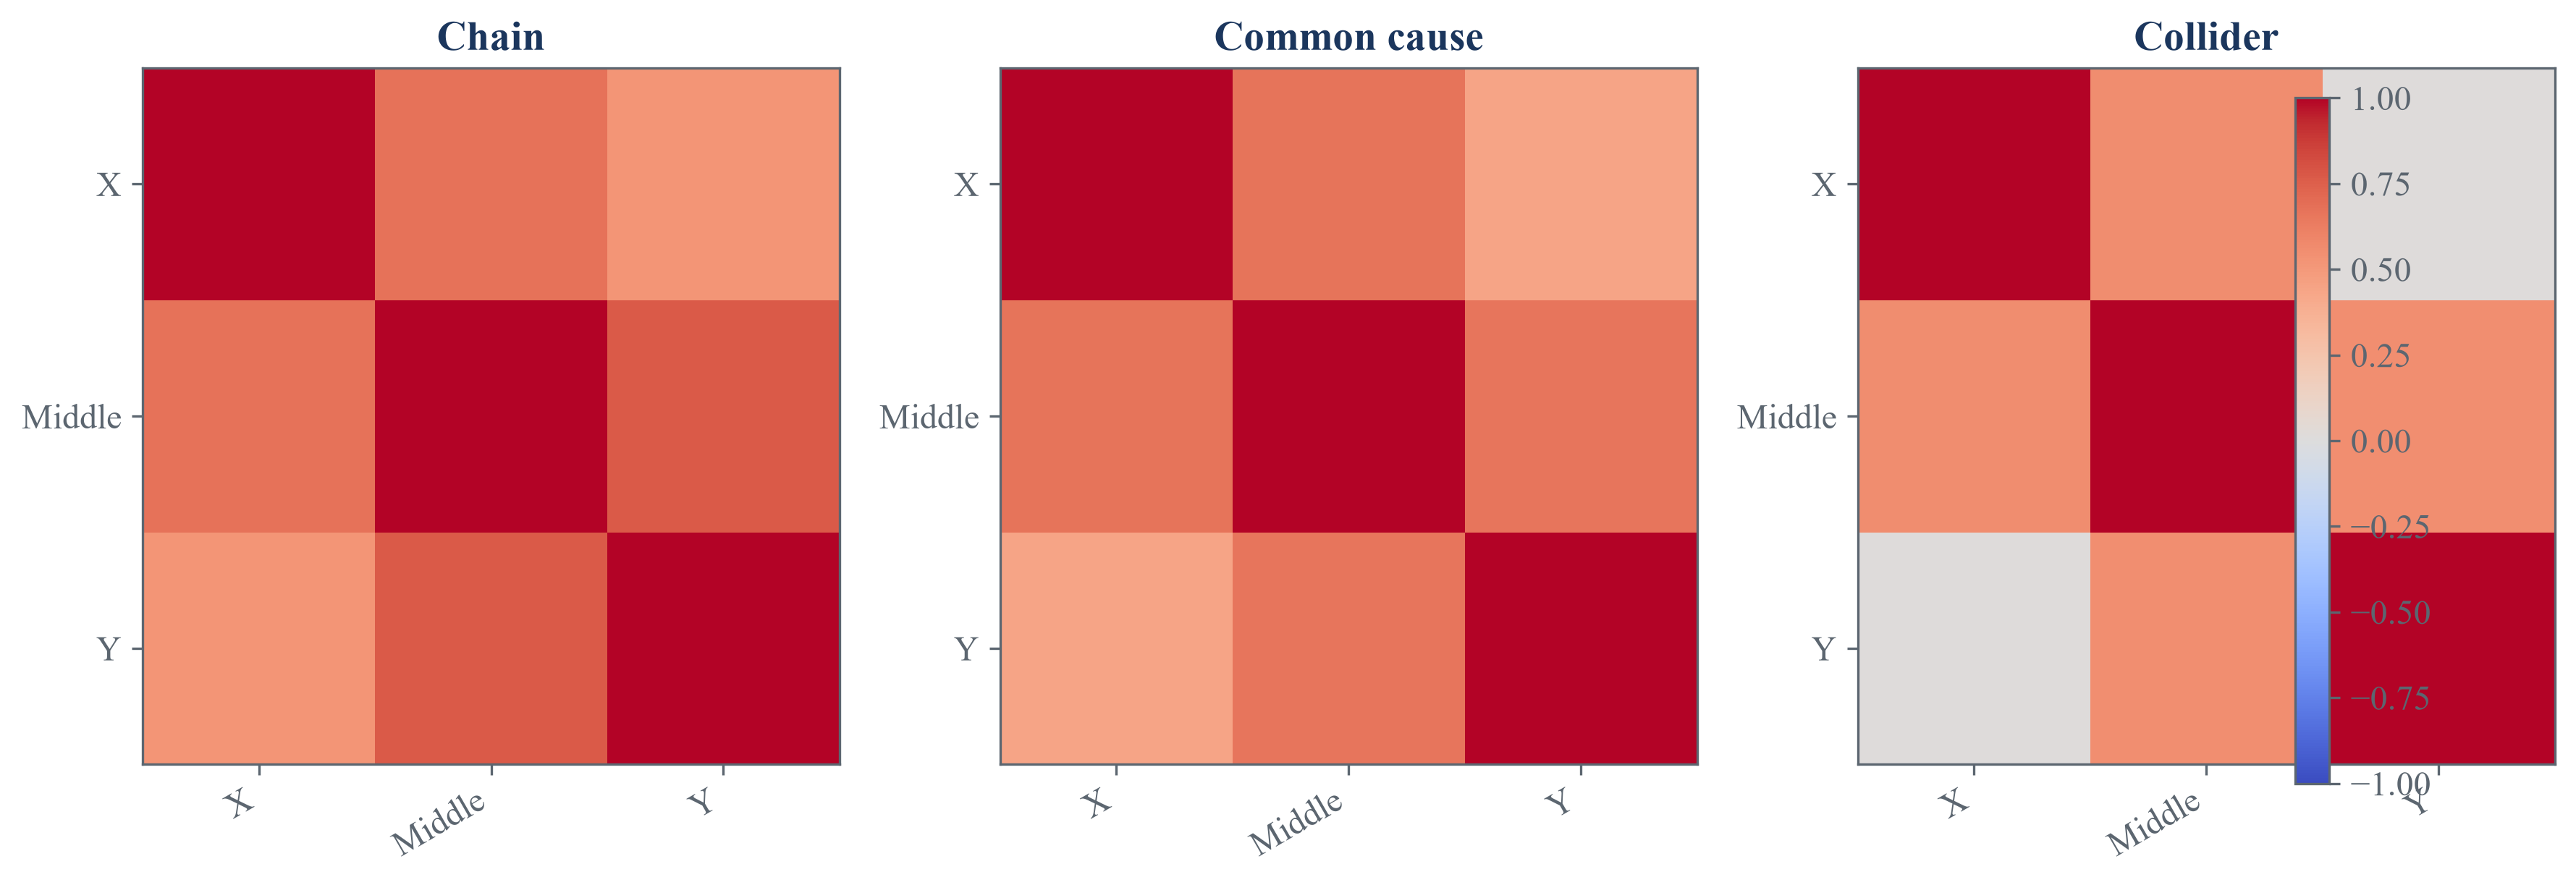

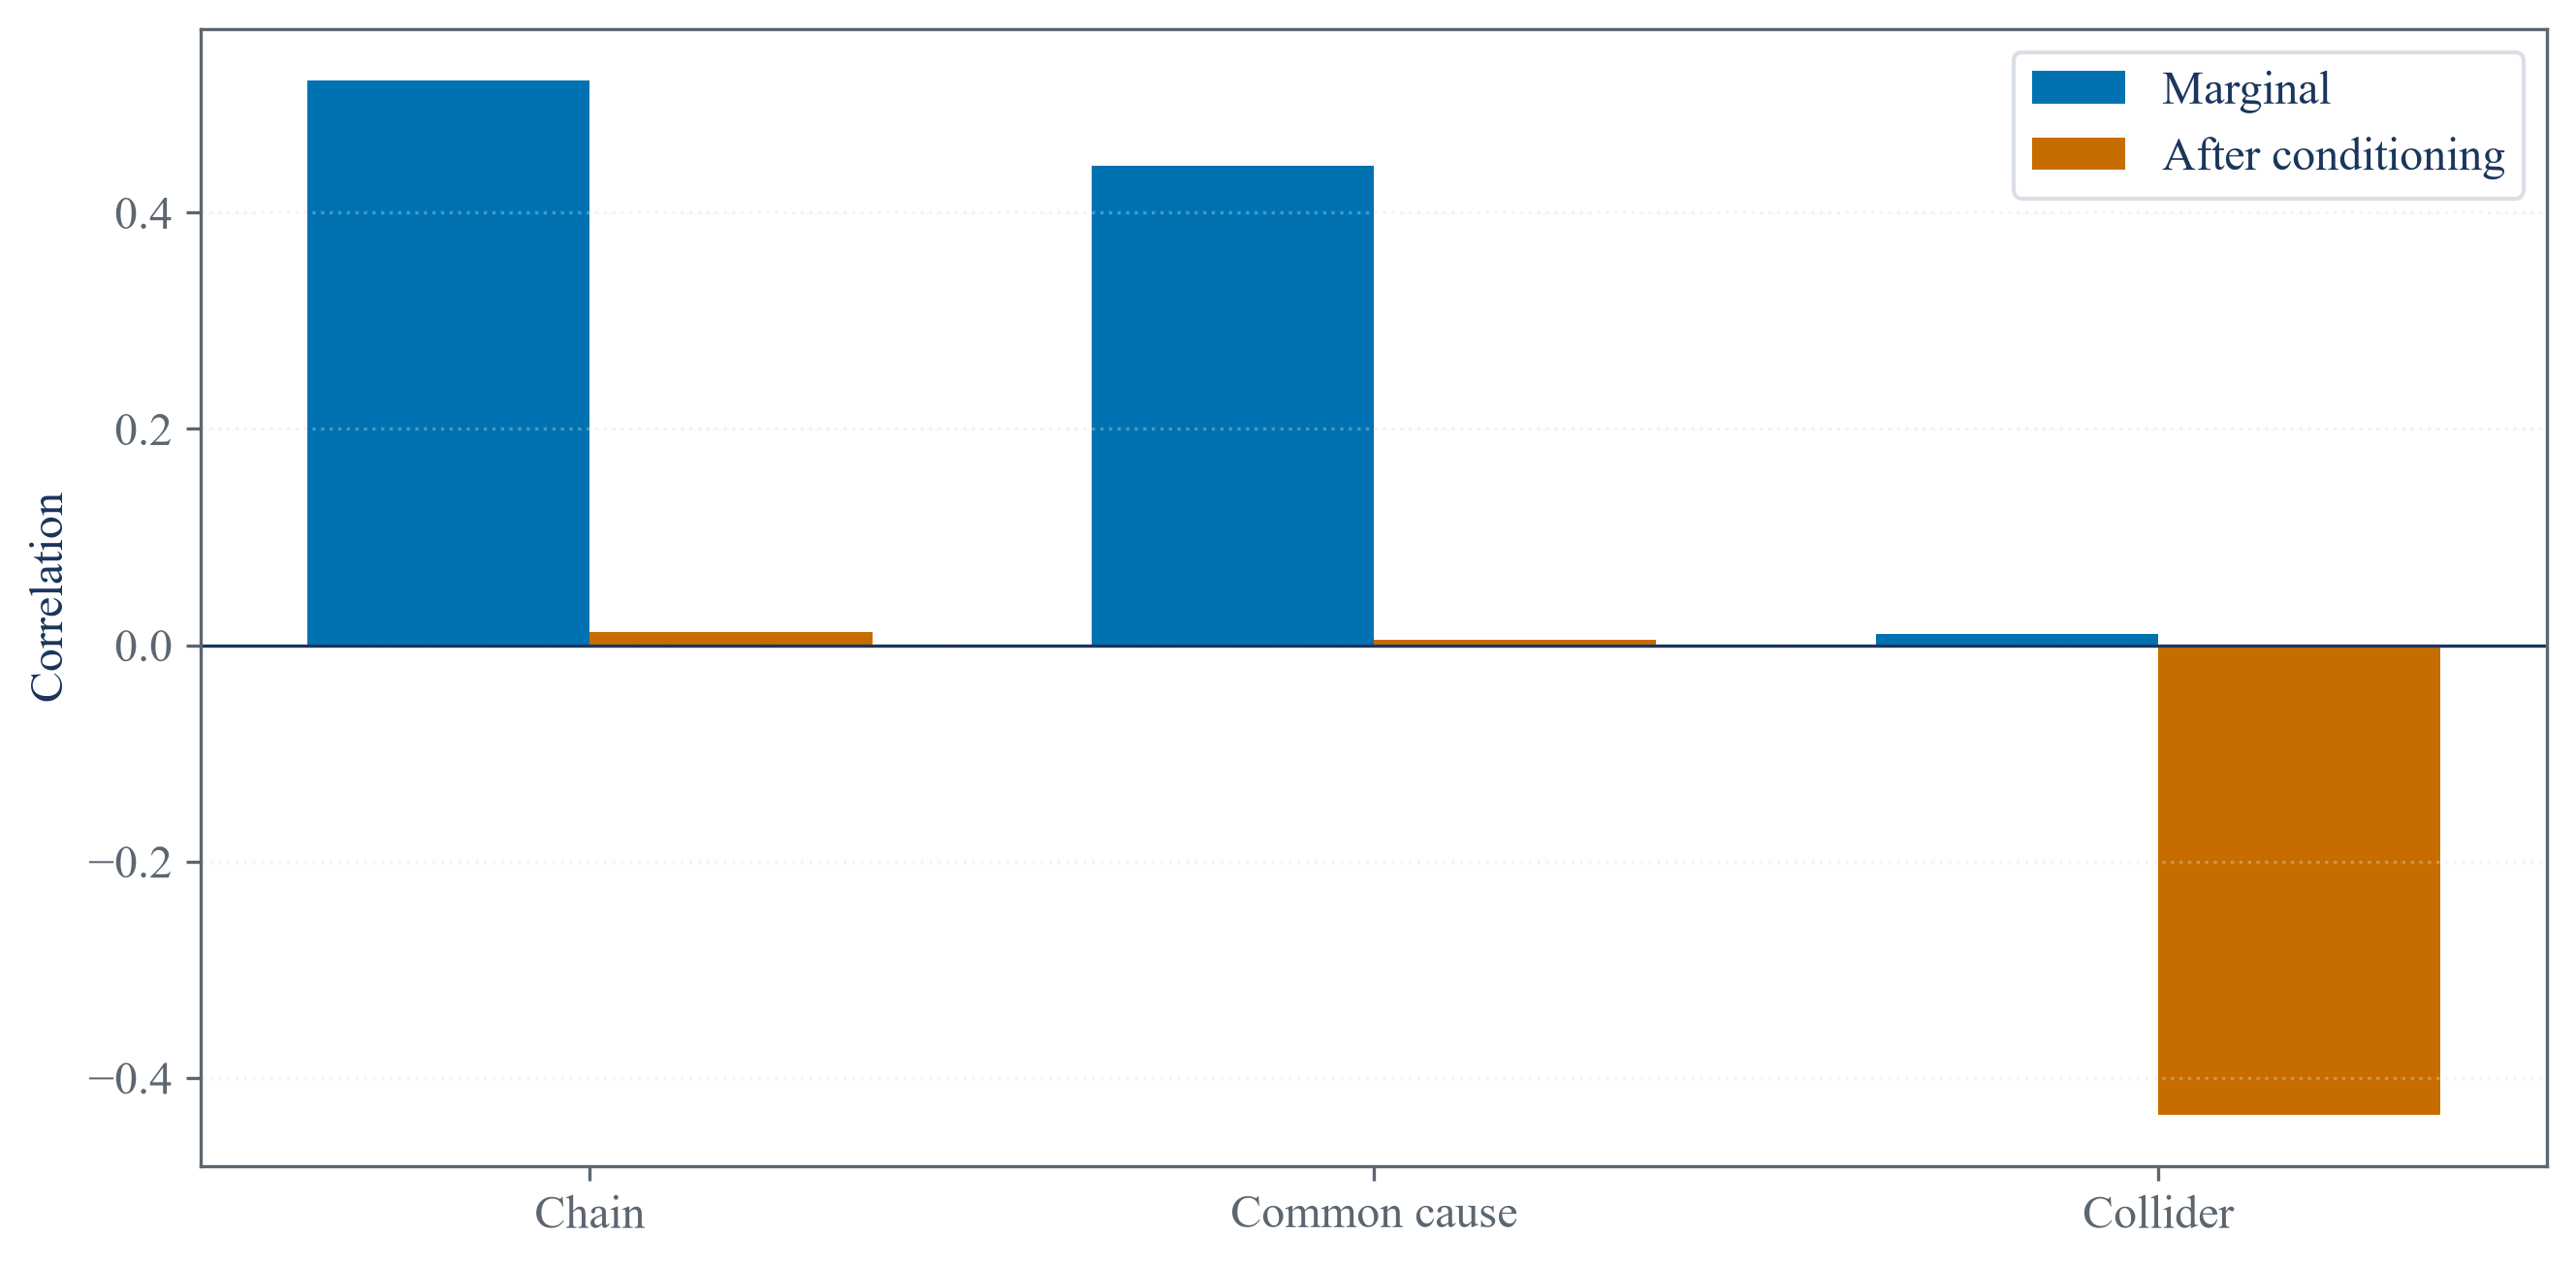

In [4]:
sample_size = 20000
coefficient = 0.9
rng = np.random.default_rng(2301)
samples = {}

x_chain = rng.normal(size=sample_size)
m_chain = coefficient * x_chain + rng.normal(size=sample_size)
y_chain = coefficient * m_chain + rng.normal(size=sample_size)
samples["Chain"] = pd.DataFrame({"X": x_chain, "Middle": m_chain, "Y": y_chain})

c_fork = rng.normal(size=sample_size)
x_fork = coefficient * c_fork + rng.normal(size=sample_size)
y_fork = coefficient * c_fork + rng.normal(size=sample_size)
samples["Common cause"] = pd.DataFrame({"X": x_fork, "Middle": c_fork, "Y": y_fork})

x_collider = rng.normal(size=sample_size)
y_collider = rng.normal(size=sample_size)
k_collider = coefficient * x_collider + coefficient * y_collider + rng.normal(size=sample_size)
samples["Collider"] = pd.DataFrame({"X": x_collider, "Middle": k_collider, "Y": y_collider})

association_rows = []
for name, frame in samples.items():
    association_rows.append({"Motif": name, "Observations": len(frame), "Marginal correlation": partial_correlation(frame["X"], frame["Y"]), "Correlation after conditioning": partial_correlation(frame["X"], frame["Y"], frame[["Middle"]]), "Absolute change": abs(partial_correlation(frame["X"], frame["Y"], frame[["Middle"]]) - partial_correlation(frame["X"], frame["Y"]))})
motif_association_summary = pd.DataFrame(association_rows)
save_table(motif_association_summary, "motif_association_summary", "Marginal and conditional associations in the known-graph examples.", "tab:chapter23-motif-associations")
display(motif_association_summary)

figure, axes = plt.subplots(1, 3, figsize=(12, 4.1))
for axis, (name, frame) in zip(axes, samples.items()):
    image = axis.imshow(frame.corr().to_numpy(dtype=float), vmin=-1, vmax=1, cmap="coolwarm")
    axis.set_title(name)
    axis.set_xticks(range(3), ["X", "Middle", "Y"], rotation=30, ha="right")
    axis.set_yticks(range(3), ["X", "Middle", "Y"])
figure.colorbar(image, ax=axes, fraction=0.018, pad=0.02)
figure.tight_layout()
save_figure(figure, "motif_sample_correlations")

figure, axis = plt.subplots(figsize=(9, 4.5))
positions = np.arange(len(motif_association_summary))
width = 0.36
axis.bar(positions - width / 2, motif_association_summary["Marginal correlation"], width, label="Marginal", color=palette["cyan"])
axis.bar(positions + width / 2, motif_association_summary["Correlation after conditioning"], width, label="After conditioning", color=palette["amber"])
axis.axhline(0, color=palette["text"], linewidth=0.8)
axis.set_xticks(positions, motif_association_summary["Motif"])
axis.set_ylabel("Correlation")
axis.legend()
axis.grid(axis="y", alpha=0.35)
figure.tight_layout()
save_figure(figure, "motif_conditioning_effects")

## Reading conditional independence through d-separation

Graph separation implies conditional independence for every distribution compatible with the graph:

$$
X\perp_G Y\mid S\quad\Longrightarrow\quad X\perp Y\mid S.
$$

Here, $X$ and $Y$ are disjoint node sets, $S$ is the conditioning set, $\perp_G$ denotes d-separation in graph $G$, $\perp$ denotes conditional independence in the probability distribution, and the implication requires compatibility between the distribution and the graph.

,Motif,Conditioning set,Paths,Active paths,d-separated
0,Chain,None,1,1,False
1,Chain,M,1,0,True
2,Common cause,None,1,1,False
3,Common cause,C,1,0,True
4,Collider,None,1,0,True
5,Collider,K,1,1,False


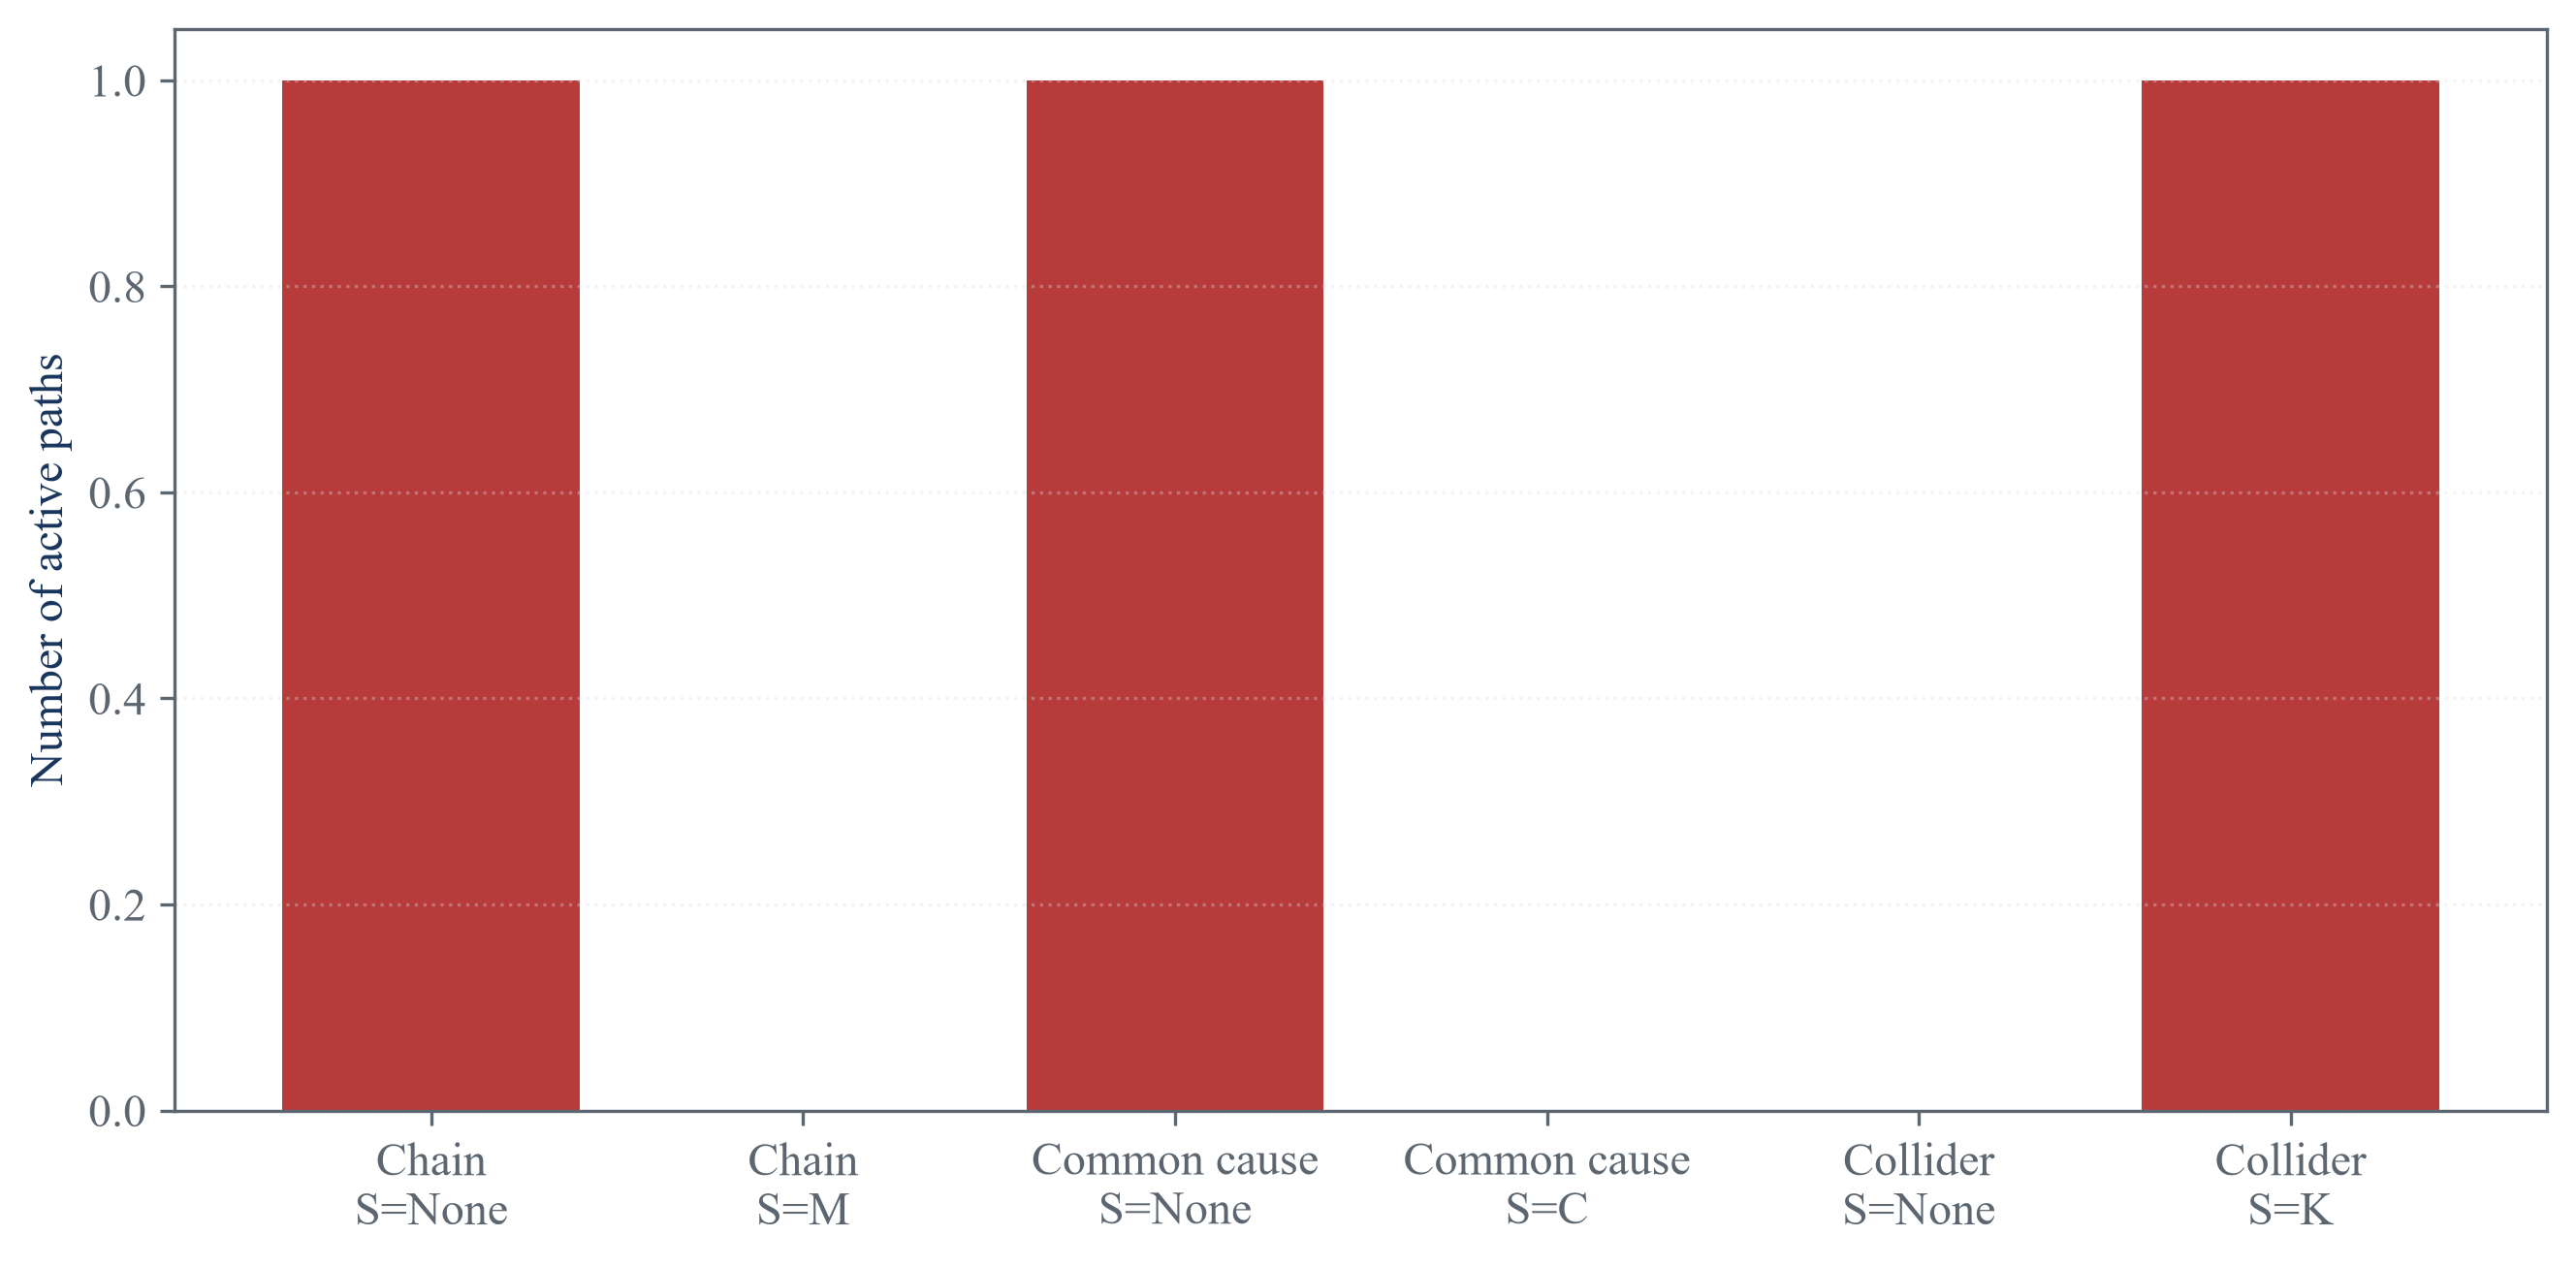

In [5]:
dseparation_rows = []
for name, graph in motifs.items():
    middle = {"Chain": "M", "Common cause": "C", "Collider": "K"}[name]
    for conditioned in [set(), {middle}]:
        records = path_records(graph, "X", "Y", conditioned)
        active_path_count = sum(record["Active"] for record in records)
        dseparation_rows.append({"Motif": name, "Conditioning set": middle if conditioned else "None", "Paths": len(records), "Active paths": active_path_count, "d-separated": active_path_count == 0})
dseparation_grid = pd.DataFrame(dseparation_rows)
save_table(dseparation_grid, "dseparation_grid", "D-separation decisions for the elementary motifs.", "tab:chapter23-dseparation-grid")
display(dseparation_grid)

figure, axis = plt.subplots(figsize=(9, 4.5))
grid_labels = [f"{row['Motif']}\nS={row['Conditioning set']}" for _, row in dseparation_grid.iterrows()]
axis.bar(grid_labels, dseparation_grid["Active paths"], color=[palette["rose"] if value else palette["green"] for value in dseparation_grid["Active paths"]])
axis.set_ylabel("Number of active paths")
axis.grid(axis="y", alpha=0.35)
figure.tight_layout()
save_figure(figure, "dseparation_active_path_counts")

## Observational Equivalence

Two directed acyclic graphs are observationally equivalent when they encode the same conditional-independence model:

$$
\mathcal M(G_1)=\mathcal M(G_2)\quad\Longleftrightarrow\quad \operatorname{skel}(G_1)=\operatorname{skel}(G_2)\ \text{ and }\ \operatorname{col}(G_1)=\operatorname{col}(G_2).
$$

Here, $\mathcal M(G)$ is the set of graph-compatible distributions, $\operatorname{skel}(G)$ is the undirected skeleton, $\operatorname{col}(G)$ is the set of unshielded collider structures, and $G_1$ and $G_2$ are two candidate graphs on the same nodes.

,Graph,Edges,Unshielded colliders,Maximum covariance error,Smallest residual variance
0,Forward chain,2,0,0,1
1,Reverse chain,2,0,0,0.609756
2,Common cause,2,0,0,0.609756


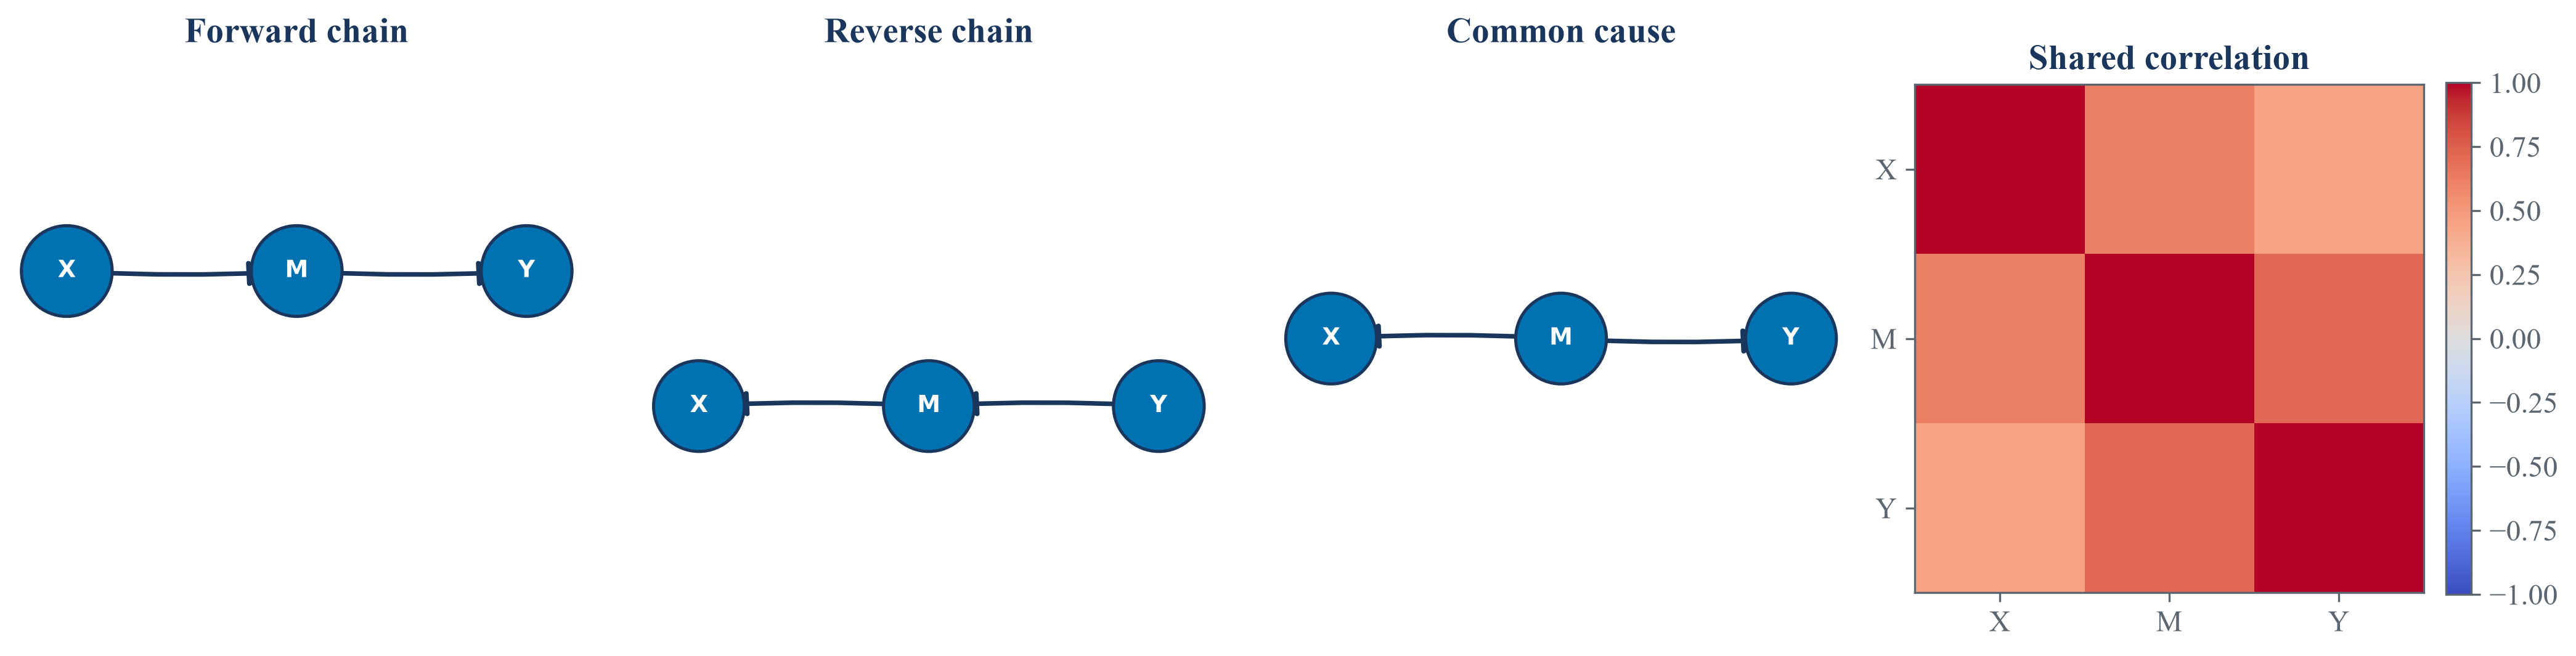

,Quantity,Value
0,Elementary graphs,3
1,Generated observations per graph,20000
2,Conditioning decisions,6
3,Equivalent graph orientations,3
4,Figures,6
5,Generated tables,9


In [6]:
equivalent_graphs = {
    "Forward chain": nx.DiGraph([("X", "M"), ("M", "Y")]),
    "Reverse chain": nx.DiGraph([("Y", "M"), ("M", "X")]),
    "Common cause": nx.DiGraph([("M", "X"), ("M", "Y")]),
}
a_value = 0.8
b_value = 0.8
theoretical_covariance = np.array([[1.0, a_value, a_value * b_value], [a_value, a_value ** 2 + 1.0, b_value * (a_value ** 2 + 1.0)], [a_value * b_value, b_value * (a_value ** 2 + 1.0), b_value ** 2 * (a_value ** 2 + 1.0) + 1.0]])
equivalent_rows = []
for name, graph in equivalent_graphs.items():
    coefficients, residual_variances, implied = fit_sem_covariance(theoretical_covariance, graph, ["X", "M", "Y"])
    equivalent_rows.append({"Graph": name, "Edges": graph.number_of_edges(), "Unshielded colliders": 0, "Maximum covariance error": float(np.max(np.abs(implied - theoretical_covariance))), "Smallest residual variance": float(residual_variances.min())})
markov_equivalence_summary = pd.DataFrame(equivalent_rows)
save_table(markov_equivalence_summary, "markov_equivalence_summary", "Three observationally equivalent factorizations of one covariance matrix.", "tab:chapter23-markov-equivalence")
display(markov_equivalence_summary)

figure, axes = plt.subplots(1, 4, figsize=(14, 3.6))
common_positions = {"X": (0, 0), "M": (1, 0), "Y": (2, 0)}
for axis, (name, graph) in zip(axes[:3], equivalent_graphs.items()):
    draw_directed_graph(axis, graph, common_positions, name)
correlation = theoretical_covariance / np.sqrt(np.outer(np.diag(theoretical_covariance), np.diag(theoretical_covariance)))
image = axes[3].imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
axes[3].set_title("Shared correlation")
axes[3].set_xticks(range(3), ["X", "M", "Y"])
axes[3].set_yticks(range(3), ["X", "M", "Y"])
figure.colorbar(image, ax=axes[3], fraction=0.046, pad=0.04)
figure.tight_layout()
save_figure(figure, "markov_equivalent_factorizations")

section_summary = pd.DataFrame({"Quantity": ["Elementary graphs", "Generated observations per graph", "Conditioning decisions", "Equivalent graph orientations", "Figures", "Generated tables"], "Value": [len(motifs), sample_size, len(dseparation_grid), len(equivalent_graphs), 6, 9]})
save_table(section_summary, "dag_section_summary", "Section 23.1 numerical summary.", "tab:chapter23-dag-section-summary")
display(section_summary)

## Tests

In [7]:
assert all(nx.is_directed_acyclic_graph(graph) for graph in motifs.values())
assert graph_structure_summary["Nodes"].eq(3).all()
assert graph_structure_summary["Directed edges"].eq(2).all()
assert len(motif_path_status) == 6
assert motif_path_status["Active"].tolist() == [True, False, True, False, False, True]
assert len(motif_factorizations) == 3
assert len(motif_association_summary) == 3
assert abs(motif_association_summary.loc[motif_association_summary["Motif"] == "Chain", "Correlation after conditioning"].iloc[0]) < 0.03
assert abs(motif_association_summary.loc[motif_association_summary["Motif"] == "Common cause", "Correlation after conditioning"].iloc[0]) < 0.03
assert motif_association_summary.loc[motif_association_summary["Motif"] == "Collider", "Correlation after conditioning"].iloc[0] < -0.35
assert len(dseparation_grid) == 6
assert dseparation_grid["d-separated"].tolist() == [False, True, False, True, True, False]
assert len(markov_equivalence_summary) == 3
assert markov_equivalence_summary["Maximum covariance error"].max() < 1e-12
assert markov_equivalence_summary["Smallest residual variance"].min() > 0.0
assert len(section_summary) == 6
for stem in ["elementary_causal_motifs", "motif_sample_correlations", "motif_conditioning_effects", "dseparation_active_path_counts", "markov_equivalent_factorizations"]:
    assert (FIGURES / f"{stem}.pdf").is_file()
for stem in ["motif_definitions", "motif_edges", "graph_structure_summary", "motif_factorizations", "motif_association_summary", "dseparation_grid", "markov_equivalence_summary", "dag_section_summary"]:
    assert (TABLES / f"{stem}.tex").is_file()